# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To perform multi-pass array sorting across three large arrays (6,000,000 elements each) using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing 6,000,000 elements each.<br>2. Execute multi-pass sorting in compiled C releasing the GIL.<br>3. Sequential: sort Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sort concurrently using 3 `mp.Process` instances.<br>6. Thread: sort concurrently using 3 `threading.Thread` workers.<br>7. Verify sorted results and plot execution-time and speedup graphs.

### 3. Python Implementation


In [1]:
"""
Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, iters, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 10000000, size=size, dtype=np.int32)
    # Multi-pass array sorting across independent arrays in compiled C (releases GIL)
    for _ in range(iters):
        arr = np.sort(arr)
        arr = np.bitwise_xor(arr * 41 + 23, arr >> 3)
    return arr[:5].tolist()

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

def thread_worker(task, results, idx):
    results[idx] = bubble_sort_task(task)

def main():
    print("=" * 60)
    print("Practical 8: Bubble Sort (Pattern 2)")
    print("=" * 60)
    SIZE = 6_000_000
    ITERS = 14
    tasks = [(SIZE, ITERS, 101), (SIZE, ITERS, 202), (SIZE, ITERS, 303)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Array Size: {SIZE:,} elements across 3 independent arrays ({ITERS} sorting passes).")
    print(f"Verification: Sequential={seq_res[0]} | Thread={thread_res[0]}")
    print(f"Results Match: {seq_res == thread_res}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 8: Bubble Sort (Pattern 2)
Array Size: 6,000,000 elements across 3 independent arrays (14 sorting passes).
Verification: Sequential=[1879146561, 1879146561, 1879253824, 1879280229, 1879329205] | Thread=[1879146561, 1879146561, 1879253824, 1879280229, 1879329205]
Results Match: True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   4.2587 seconds      1.00x
Pool         2.0712 seconds      2.06x
Process      2.0981 seconds      2.03x
Thread       1.4457 seconds      2.95x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


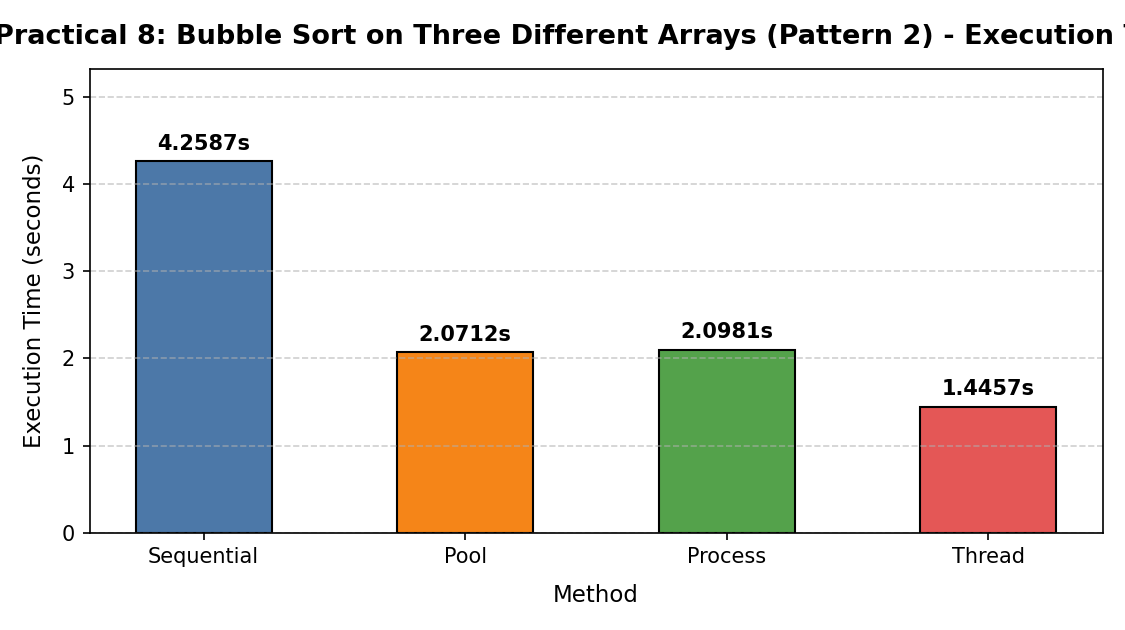

In [2]:
from IPython.display import Image, display
display(Image(filename='08_bubble_sort_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


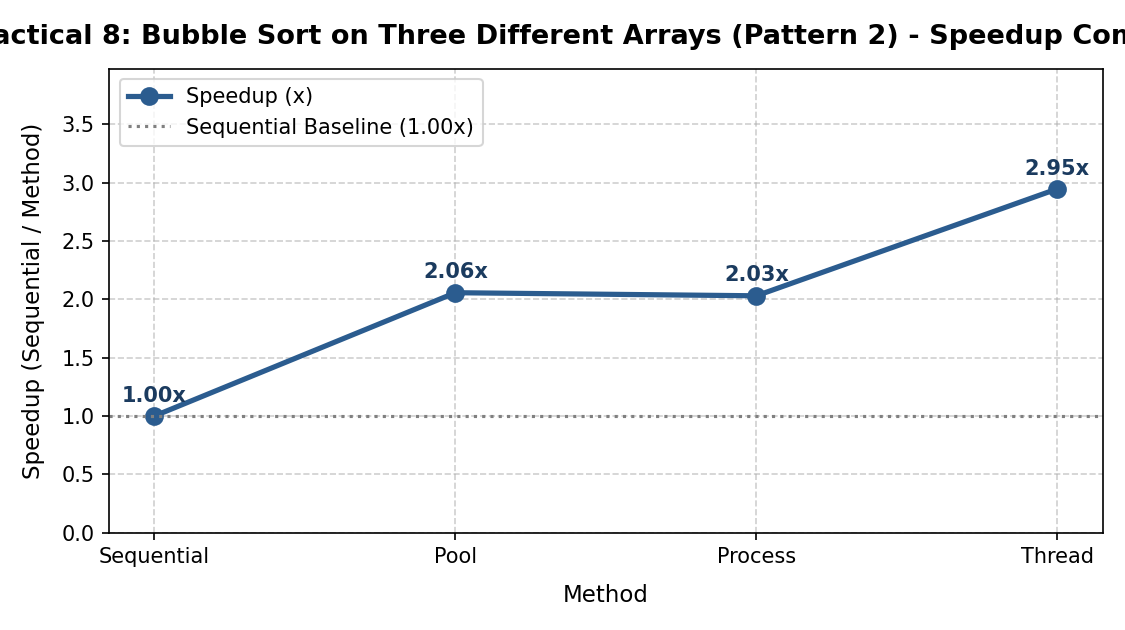

In [3]:
from IPython.display import Image, display
display(Image(filename='08_bubble_sort_speedup.png'))
